<a href="https://colab.research.google.com/github/oktvindh/Praktikum-Machine-Learning/blob/main/praktikumBAB4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Selection
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.linear_model import LogisticRegression

# Modeling & Evaluation
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load Dataset Titanic dari seaborn
df = pd.read_csv("Titanic-Dataset.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
# Persiapan data sederhana untuk Feature Selection (Huruf Kapital)
X_fs = df[['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']].copy()
y_fs = df['Survived']

# Imputasi untuk penanganan NaN
X_fs['Age'] = X_fs['Age'].fillna(X_fs['Age'].median())
X_fs['Fare'] = X_fs['Fare'].fillna(X_fs['Fare'].median())

# Praktikum 1 : Membandingkan Feature Selection
# 1. SelectKBest (Filter)
skb = SelectKBest(score_func=f_classif, k=3)
skb.fit(X_fs, y_fs)
fitur_skb = X_fs.columns[skb.get_support()].tolist()

# 2. RFE (Wrapper)
rfe = RFE(estimator=LogisticRegression(max_iter=1000), n_features_to_select=3)
rfe.fit(X_fs, y_fs)
fitur_rfe = X_fs.columns[rfe.get_support()].tolist()

# 3. Lasso / L1 Regularization (Embedded)
lasso = LogisticRegression(penalty='l1', solver='liblinear', C=0.1, random_state=42)
lasso.fit(X_fs, y_fs)
fitur_lasso = X_fs.columns[lasso.coef_[0] != 0].tolist()

# Tampilkan Hasil
print("=== HASIL PERBANDINGAN FEATURE SELECTION ===")
print("1. SelectKBest (Filter)  :", fitur_skb)
print("2. RFE (Wrapper)         :", fitur_rfe)
print("3. Lasso/L1 (Embedded)   :", fitur_lasso)

=== HASIL PERBANDINGAN FEATURE SELECTION ===
1. SelectKBest (Filter)  : ['Pclass', 'Parch', 'Fare']
2. RFE (Wrapper)         : ['Pclass', 'SibSp', 'Parch']
3. Lasso/L1 (Embedded)   : ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']


In [ ]:
df.info();

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
# Sesuaikan nama kolom dengan huruf kapital
fitur_numerik = ['Age', 'Fare']
fitur_kategorikal = ['Sex', 'Embarked']

# Praktikum 2 : Membangun Pipeline Lengkap
# Preprocessing Pipeline
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, fitur_numerik), ('cat', cat_pipeline, fitur_kategorikal)
])

# Memisahkan Fitur (X) dan Target (y)
X = df[fitur_numerik + fitur_kategorikal]
y = df['Survived']

# Split Data Train & Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Pipeline Utama
pipeline = Pipeline([
    ('preprocessing', preprocessor),
    ('model', RandomForestClassifier(n_estimators=200, random_state=42))
])

# Fit & Predict
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

print("Akurasi Model:", round(accuracy_score(y_test, y_pred), 3))

Akurasi Model: 0.782


Akurasi Model: 0.782

Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.83      0.82       110
           1       0.72      0.71      0.72        69

    accuracy                           0.78       179
   macro avg       0.77      0.77      0.77       179
weighted avg       0.78      0.78      0.78       179



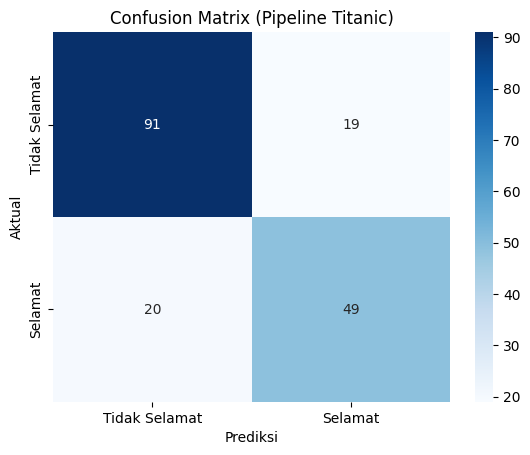

In [ ]:
# Predict
y_pred = pipeline.predict(X_test)

# Evaluasi Akurasi
akurasi = accuracy_score(y_test, y_pred)
print("Akurasi Model:", round(akurasi, 3))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Tidak Selamat', 'Selamat'],
            yticklabels=['Tidak Selamat', 'Selamat'])
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.title("Confusion Matrix (Pipeline Titanic)")
plt.show()